# Профили рейтинговых бинов по утилити (Cache, Premier)

Ноутбук 1 из 2. Строим поведенческие профили утилити для 5 рейтинговых бинов по игрокам-матчам с известным `PremierRatingNew`.
Ноутбук 2 по этим профилям относит любого игрока (с рейтингом или без) к бину и сравнивает его с профилем бина.
Разделение рейтинга на 5 бинов было сделано исходя из разделения рангов в кс го, потому что в данных не было очевидного разделения: 

`(сильверы (1-6), звезды (1-4), калаши (1, 2, с венками), беркут + лем, суприм + глобал = 5 бинов)`

## Содержание

Коротко: профили утилити для 5 квантильных бинов рейтинга, их потом использует ноутбук 2.

1. **Введение и цель** — зачем нужны профили бинов и как их использует ноутбук 2.
2. **Ограничения** — каких данных нет; рейтинг известен только у 24.4% игроков-матчей.
3. **Загрузка данных и рейтинговые бины** — parquet-кэш, 5 квантильных бинов, границы и численность.
4. **Профиль по бину: микс гранат** — доли смоков, флешек, HE, молотовов и гранат за раунд.
5. **Профиль по бину: эффективность флешей** — враги и тиммейты на флешку, пустые флешки, flash-kill.
6. **Профиль по бину: эффективность HE** — урон за бросок и доля HE без урона.
7. **Профиль по бину: молотов** — урон за бросок, доля без урона, оговорка про area denial.
8. **Профиль по бину: тайминг бросков по раунду** — среднее время броска от начала раунда (прокси).
9. **Сводная таблица профилей бинов** — бин × метрика, эту таблицу читает ноутбук 2.
10. **Выводы по бинам** — чем каждый бин отличается от соседних, без выводов о причинах.
11. **Экспорт профиля для ноутбука 2** — файл `rating_bin_profiles.parquet` и его схема.

## 1. Введение и цель

**Цель:** описать каждый из 5 рейтинговых бинов набором метрик утилити, чтобы потом отнести любого игрока к бину
и сравнить его с профилем бина.

Единица анализа — **пара «игрок–матч»** с известным рейтингом. Для каждой пары считаем метрики утилити за матч,
потом усредняем их внутри бина. Среднее по бину — это «центроид»: ноутбук 2 сравнивает с ним метрики игрока
(в том числе методом ближайшего центроида для игроков без рейтинга).

Загрузка и производные признаки — те же, что в `notebooks/eda.ipynb` и `notebooks/player_utility_analysis.ipynb`.

**Главный вывод (числа — в разделе 10): утилити почти не разделяет рейтинговые бины.** Средние бинов по многим метрикам
различаются достоверно (95% ДИ узкие), но сами различия малы на фоне разброса игроков внутри бина: только у `nades_per_round`
размах B1–B5 ≈ 0.6 внутрибинового std, у остальных 16 метрик — меньше 0.3, у многих — меньше 0.1. Типичный игрок-матч из B1
и из B5 по утилити почти неотличим, поэтому отнесение к бину по утилити в ноутбуке 2 — грубая оценка.

См. также: `docs/poc_findings_summary.md` — сводка этого вывода для всего POC.

## 2. Ограничения

- **Рейтинг известен только у 24.4% игроков-матчей** (24 393 из 99 921). Это главное ограничение:
  - **статистическая мощность.** Бины строятся по четверти данных, в каждом ~4.8–5k игроков-матчей, а по отдельным типам гранат
    после порога (см. ниже) остаётся ещё меньше;
  - **поэтому ноутбуку 2 нужен запасной путь для игроков без рейтинга.** У ~76% игроков-матчей бин по рейтингу определить нельзя,
    и их придётся относить к бину по сходству профиля (ближайший центроид), а не по рейтингу.
  - Игроки с рейтингом — не случайная выборка: рейтинг есть в Premier-матчах и только у откалиброванных/открытых профилей.
    Профили бинов могут не переноситься один в один на игроков без рейтинга.
- **Только утилити.** Нет стрельбы и аима, движения вне моментов броска, экономики (денег и закупа), смертей не от гранат
  и исходов раундов. Рейтинг зависит от всего этого, а мы видим только гранаты.
- **Урон HE и огня по своим не записан** (`DamagedPlayers` содержит только врагов, см. EDA 1.2). «Тимдамаг» оцениваем только по флешкам.
- **Нет начала раунда.** Тайминг в разделе 8 считаем от первой гранаты раунда (любого игрока) — это прокси.
- **Маленькие выборки на игрока-матч.** За матч игрок бросает несколько гранат каждого типа. Поэтому метрику по типу считаем,
  только если бросков этого типа **≥ 3**; сколько пар это отбрасывает — показано в каждом разделе.
- **Корреляция, а не причинность.** «В бине X в среднем больше урона HE» не значит, что урон HE поднимает рейтинг.

## 3. Загрузка данных и рейтинговые бины

Те же константы и стиль, что в `eda.ipynb`. Читаем готовый parquet-кэш из `data/processed/`
(его строит `flatten()` в `eda.ipynb`); исходный pickle здесь не нужен.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 90
plt.rcParams['figure.figsize'] = (10, 4.5)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

CACHE_DIR = '../data/processed'
PROFILE_PATH = os.path.join(CACHE_DIR, 'rating_bin_profiles.parquet')
TICKRATE = 64  # проверено в eda.ipynb: фитиль HE/флешки = 104 тика = 1.625 с
GT_ORDER = ['smoke', 'flash', 'he', 'molotov']
GT_COLORS = {'smoke': '#7f7f7f', 'flash': '#e5ae38', 'he': '#2ca02c', 'molotov': '#d62728'}
N_BINS = 5   # квантильные бины рейтинга
MIN_N = 3    # минимум бросков типа за матч, чтобы считать метрику по этому типу
KEY = ['match_id', 'thrower_id']

In [2]:
throws, damage, flashed, players = (pd.read_parquet(os.path.join(CACHE_DIR, f'{n}.parquet'))
                                    for n in ['throws', 'damage', 'flashed', 'players'])
for name, df in [('throws', throws), ('damage', damage), ('flashed', flashed), ('players', players)]:
    print(f'{name:8s} {df.shape[0]:>10,} строк × {df.shape[1]:>2} колонок')

throws    2,385,417 строк × 30 колонок
damage      344,524 строк × 11 колонок
flashed   1,001,026 строк × 14 колонок
players      99,921 строк ×  3 колонок


### 3.1 Производные признаки

Как в `player_utility_analysis.ipynb` (раздел 3.2), сводим исходы на уровень броска. `throw_idx` в `damage`/`flashed` — это номер
строки в `throws`, поэтому джойны делаем до любой фильтрации.
- HE / огонь: урон по врагам (HP и броня);
- флешка: число ослеплённых врагов и тиммейтов, `flash_kills` — враг убит, пока ослеплён этой флешкой (кем угодно);
- `t_in_round` — секунды от первой гранаты раунда (любого игрока) до броска;
- `rounds_in_match` — макс. раунд с гранатой + 1 (как в EDA).

In [3]:
meta = throws[['team', 'thrower_id']]
damage = damage.join(meta, on='throw_idx')
flashed = flashed.join(meta, on='throw_idx')
for df in (damage, flashed):
    df['rel'] = np.select([df['victim_id'] == df['thrower_id'], df['victim_team'] == df['team']],
                          ['self', 'team'], 'enemy')

# HE / огонь: DamagedPlayers содержит только врагов
en = damage[damage['rel'] == 'enemy'].groupby('throw_idx').agg(
    enemy_dmg=('health_dmg', 'sum'), enemy_armor_dmg=('armor_dmg', 'sum'))
# флешки: сколько ослеплено врагов / тиммейтов, убийства ослеплённых врагов
fl_n = flashed.groupby(['throw_idx', 'rel']).size().unstack(fill_value=0)
fl_n = fl_n.reindex(columns=['enemy', 'team'], fill_value=0).add_prefix('n_flashed_')
fl_k = flashed[flashed['rel'] == 'enemy'].groupby('throw_idx').agg(flash_kills=('killed', 'sum'))
throws = throws.join(en).join(fl_n).join(fl_k)

is_dmg = throws['grenade_type'].isin(['he', 'molotov'])
is_fl = throws['grenade_type'] == 'flash'
for c in ['enemy_dmg', 'enemy_armor_dmg']:
    throws[c] = throws[c].where(~is_dmg, throws[c].fillna(0)).astype('float32')
for c in ['n_flashed_enemy', 'n_flashed_team', 'flash_kills']:
    throws[c] = throws[c].where(~is_fl, throws[c].fillna(0)).astype('float32')
throws['dmg_total'] = throws['enemy_dmg'] + throws['enemy_armor_dmg']

round_t0 = throws.groupby(['match_id', 'round'])['start_tick'].transform('min')
throws['t_in_round'] = (throws['start_tick'] - round_t0) / TICKRATE
rounds_in_match = throws.groupby('match_id')['round'].max() + 1

summary_cols = ['enemy_dmg', 'dmg_total', 'n_flashed_enemy', 'n_flashed_team', 't_in_round']
preview = throws.groupby('grenade_type')[summary_cols].mean()
preview.insert(0, 'n_throws', throws.groupby('grenade_type').size())
preview = preview.reindex(GT_ORDER)
preview.style.format('{:.2f}', subset=summary_cols, na_rep='не определено для типа').format('{:d}', subset=['n_throws'])

,n_throws,enemy_dmg,dmg_total,n_flashed_enemy,n_flashed_team,t_in_round
grenade_type,,,,,,
smoke,729947,не определено для типа,не определено для типа,не определено для типа,не определено для типа,15.15
flash,643914,не определено для типа,не определено для типа,0.75,0.45,18.96
he,565392,8.73,13.58,не определено для типа,не определено для типа,22.54
molotov,446164,2.43,2.43,не определено для типа,не определено для типа,23.82


### 3.2 Квантильные бины рейтинга

Берём пары «игрок–матч» с известным рейтингом и режем рейтинг на **5 квантилей** (`pd.qcut`). Естественных разрывов в распределении
нет (оно унимодальное, проверено ранее), поэтому равные по численности бины — самый честный вариант.

**Это когортный анализ на уровне игрока-матча, а не игрока.** Если один `player_id` встречается в нескольких матчах с разным рейтингом,
каждая пара попадает в свой бин независимо. Это нормально: рейтинг меняется между матчами, а профиль описывает
«как играют утилити в матче при таком рейтинге».

In [4]:
rated = (players.dropna(subset=['rating']).drop_duplicates(['match_id', 'player_id'])
         .rename(columns={'player_id': 'thrower_id'}))
bin_idx, BIN_EDGES = pd.qcut(rated['rating'], N_BINS, labels=False, retbins=True)
rated['bin'] = bin_idx + 1
BIN_LABELS = [f'B{i + 1}: {BIN_EDGES[i]:,.0f}–{BIN_EDGES[i + 1]:,.0f}' for i in range(N_BINS)]
rated['bin_label'] = pd.Categorical(rated['bin'].map(dict(enumerate(BIN_LABELS, 1))), categories=BIN_LABELS, ordered=True)
BIN_PALETTE = dict(zip(BIN_LABELS, sns.color_palette('viridis', N_BINS)))

print(f'Игроков-матчей всего: {len(players):,}; с рейтингом: {len(rated):,} ({len(rated) / len(players):.1%})')
print('Границы бинов (BIN_EDGES):', np.round(BIN_EDGES, 1).tolist())

multi = rated.groupby('thrower_id')['bin'].agg(['size', 'nunique'])
print(f'Уникальных игроков с рейтингом: {len(multi):,}; в ≥2 рейтинговых матчах: {(multi["size"] >= 2).sum():,}; '
      f'из них попадают в разные бины в разных матчах: {(multi["nunique"] > 1).sum():,}')

thrown = throws[KEY].drop_duplicates()
no_throw = len(rated) - len(rated.merge(thrown, on=KEY))
print(f'Пар с рейтингом без единого броска за матч: {no_throw:,} ({no_throw / len(rated):.1%})')

bin_tab = rated.groupby('bin_label', observed=True).agg(
    игроков_матчей=('rating', 'size'), уникальных_игроков=('thrower_id', 'nunique'),
    рейтинг_мин=('rating', 'min'), рейтинг_медиана=('rating', 'median'), рейтинг_макс=('rating', 'max'))
bin_tab['доля пар с рейтингом'] = bin_tab['игроков_матчей'] / len(rated)
bin_tab

Игроков-матчей всего: 99,921; с рейтингом: 24,393 (24.4%)
Границы бинов (BIN_EDGES): [1000.0, 8567.0, 13076.8, 16411.2, 19999.0, 30982.0]
Уникальных игроков с рейтингом: 21,535; в ≥2 рейтинговых матчах: 2,098; из них попадают в разные бины в разных матчах: 339
Пар с рейтингом без единого броска за матч: 467 (1.9%)


,игроков_матчей,уникальных_игроков,рейтинг_мин,рейтинг_медиана,рейтинг_макс,доля пар с рейтингом
bin_label,,,,,,
"B1: 1,000–8,567",4880,4458,"1,000.000","5,104.000","8,567.000",0.200
"B2: 8,567–13,077",4877,4422,"8,568.000","11,043.000","13,076.000",0.200
"B3: 13,077–16,411",4879,4354,"13,077.000","14,766.000","16,411.000",0.200
"B4: 16,411–19,999",5011,4487,"16,412.000","18,279.000","19,999.000",0.205
"B5: 19,999–30,982",4746,4155,"20,000.000","22,574.500","30,982.000",0.195


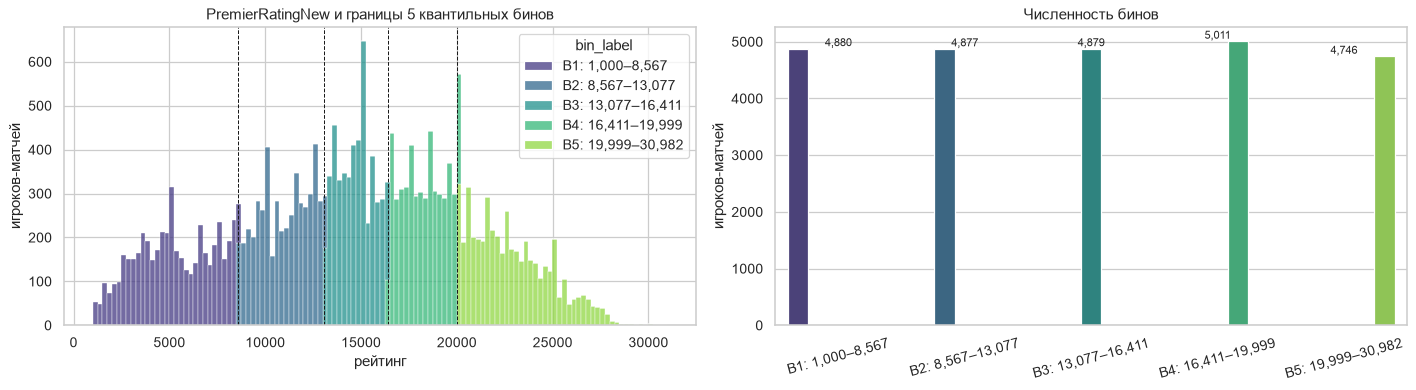

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.histplot(data=rated, x='rating', hue='bin_label', palette=BIN_PALETTE, bins=120, multiple='stack', ax=axes[0])
for e in BIN_EDGES[1:-1]:
    axes[0].axvline(e, color='k', lw=0.8, ls='--')
axes[0].set_title('PremierRatingNew и границы 5 квантильных бинов'); axes[0].set_xlabel('рейтинг'); axes[0].set_ylabel('игроков-матчей')
sns.barplot(x=bin_tab.index, y=bin_tab['игроков_матчей'], hue=bin_tab.index, palette=BIN_PALETTE, legend=False, ax=axes[1])
for i, v in enumerate(bin_tab['игроков_матчей']):
    axes[1].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
axes[1].set_title('Численность бинов'); axes[1].set_xlabel(''); axes[1].set_ylabel('игроков-матчей')
axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

Бины почти равные (~4.7–5.0k пар). Небольшой перекос у B4 и B5: граница между ними приходится на пик **19 999**. Это граница цветового тира
Premier (EDA 2.4), и много игроков стоит ровно на ней. `qcut` не режет одинаковые значения, поэтому весь пик уходит в B4.

## 4. Профиль по бину: микс гранат

Для каждой пары «игрок–матч» считаем долю каждого типа среди её бросков и усредняем по бину. Доли считаем, только если в матче
**≥ 3 броска** любых типов (`MIN_N`). Дополнительно — **гранат за раунд** (все пары, включая тех, кто ничего не бросил).
Этого нет в исходном плане, но в `player_utility_analysis.ipynb` (раздел 11) метрика сильнее всего росла с рейтингом,
поэтому она полезна как признак для ноутбука 2.

**Что показывают усы на графиках разделов 4–8:** 95% доверительный интервал **среднего** по бину (±1.96·std/√n).
Он отвечает на вопрос «насколько точно известен центроид бина» и при тысячах пар в бине очень узкий. Это **не** разброс
игроков внутри бина: внутрибиновое std в 25–35 раз шире ДИ (сравнение — в разделе 9). Неперекрывающиеся усы значат
«средние бинов различаются», но не «игроки разных бинов различаются» — это разные вопросы (раздел 10).

In [6]:
tr = throws.merge(rated[KEY + ['bin', 'bin_label']], on=KEY)  # броски только игроков-матчей с рейтингом
print(f'Бросков у пар с рейтингом: {len(tr):,} из {len(throws):,} ({len(tr) / len(throws):.1%})')

pm = rated.set_index(KEY)[['rating', 'bin', 'bin_label']]
cnt = (tr.groupby(KEY + ['grenade_type']).size().unstack(fill_value=0)
       .reindex(columns=GT_ORDER, fill_value=0).add_prefix('n_'))
pm = pm.join(cnt)
pm[cnt.columns] = pm[cnt.columns].fillna(0)
pm['n_total'] = pm[cnt.columns].sum(axis=1)
pm['rounds'] = rounds_in_match.reindex(pm.index.get_level_values('match_id')).values
pm['nades_per_round'] = pm['n_total'] / pm['rounds']
print(f"Пар без числа раундов (в матче вообще нет гранат, nades_per_round = NaN): {pm['rounds'].isna().sum()}")

MIX_FEATS = [f'share_{g}' for g in GT_ORDER]
for g in GT_ORDER:
    pm[f'share_{g}'] = (pm[f'n_{g}'] / pm['n_total']).where(pm['n_total'] >= MIN_N)


def threshold_report(n_col):
    # сколько пар в бине имеют хотя бы 1 бросок и сколько проходит порог MIN_N
    g = pm.groupby('bin_label', observed=True)[n_col]
    rep = pd.DataFrame({'пар в бине': g.size(), '≥1 бросок': g.apply(lambda s: (s > 0).sum()),
                        f'≥{MIN_N} (в профиле)': g.apply(lambda s: (s >= MIN_N).sum())})
    rep['отброшено (1..MIN_N-1)'] = rep['≥1 бросок'] - rep[f'≥{MIN_N} (в профиле)']
    rep['доля отброшенных из ≥1'] = rep['отброшено (1..MIN_N-1)'] / rep['≥1 бросок']
    return rep


display(threshold_report('n_total'))
mix_prof = pm.groupby('bin_label', observed=True)[MIX_FEATS + ['nades_per_round']].mean()
mix_prof

Бросков у пар с рейтингом: 600,825 из 2,385,417 (25.2%)
Пар без числа раундов (в матче вообще нет гранат, nades_per_round = NaN): 40


,пар в бине,≥1 бросок,≥3 (в профиле),отброшено (1..MIN_N-1),доля отброшенных из ≥1
bin_label,,,,,
"B1: 1,000–8,567",4880,4730,4517,213,0.045
"B2: 8,567–13,077",4877,4807,4655,152,0.032
"B3: 13,077–16,411",4879,4817,4726,91,0.019
"B4: 16,411–19,999",5011,4940,4876,64,0.013
"B5: 19,999–30,982",4746,4632,4558,74,0.016


,share_smoke,share_flash,share_he,share_molotov,nades_per_round
bin_label,,,,,
"B1: 1,000–8,567",0.303,0.253,0.254,0.190,0.961
"B2: 8,567–13,077",0.310,0.254,0.251,0.185,1.115
"B3: 13,077–16,411",0.318,0.253,0.248,0.180,1.200
"B4: 16,411–19,999",0.314,0.255,0.247,0.184,1.295
"B5: 19,999–30,982",0.310,0.259,0.241,0.190,1.349


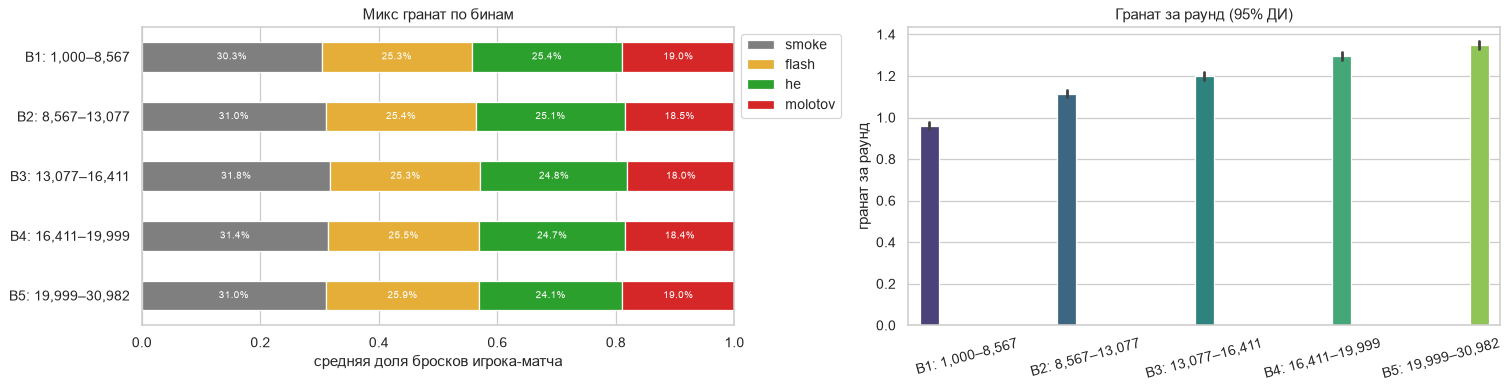

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
mix = mix_prof[MIX_FEATS].set_axis(GT_ORDER, axis=1)
mix.plot(kind='barh', stacked=True, color=[GT_COLORS[g] for g in GT_ORDER], ax=axes[0])
for i, (_, row) in enumerate(mix.iterrows()):
    left = 0
    for g in GT_ORDER:
        axes[0].text(left + row[g] / 2, i, f'{row[g]:.1%}', ha='center', va='center', fontsize=8, color='white')
        left += row[g]
axes[0].invert_yaxis(); axes[0].set_xlim(0, 1); axes[0].set_xlabel('средняя доля бросков игрока-матча'); axes[0].set_ylabel('')
axes[0].set_title('Микс гранат по бинам'); axes[0].legend(bbox_to_anchor=(1, 1))
sns.barplot(data=pm, x='bin_label', y='nades_per_round', hue='bin_label', palette=BIN_PALETTE,
            errorbar=('se', 1.96), legend=False, ax=axes[1])
axes[1].set_title('Гранат за раунд (95% ДИ)'); axes[1].set_xlabel(''); axes[1].set_ylabel('гранат за раунд')
axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

_Интерпретация — в разделе 10, после того как собраны все метрики._

## 5. Профиль по бину: эффективность флешей

Метрики на одну флешку (среднее по флешкам игрока за матч, потом по бину):
- `flash_enemies_per_flash` — врагов ослеплено (любая длительность);
- `flash_team_per_flash` — тиммейтов ослеплено (без самого бросившего). Это прокси «тимдамага» флешками: урон по своим от HE и огня в данных не записан;
- `flash_empty_share` — доля **пустых** флешек. Пустая = **не ослепила ни одного врага** (как «доля без врагов» в `player_utility_analysis.ipynb`).
  Флешка, ослепившая только своих, тоже пустая с точки зрения пользы;
- `flash_kills_per100` — ослеплённого этой флешкой врага убили, пока он слеп (кто угодно), на 100 флешек.

Метрики считаем только для пар с **≥ 3 флешками** за матч.

In [8]:
FLASH_FEATS = ['flash_enemies_per_flash', 'flash_team_per_flash', 'flash_empty_share', 'flash_kills_per100']
fb = tr[tr['grenade_type'] == 'flash'].assign(empty=lambda d: d['n_flashed_enemy'] == 0,
                                               kills100=lambda d: 100 * d['flash_kills'])
fl_pm = fb.groupby(KEY).agg(flash_enemies_per_flash=('n_flashed_enemy', 'mean'), flash_team_per_flash=('n_flashed_team', 'mean'),
                            flash_empty_share=('empty', 'mean'), flash_kills_per100=('kills100', 'mean'))
pm = pm.drop(columns=FLASH_FEATS, errors='ignore').join(fl_pm)
pm[FLASH_FEATS] = pm[FLASH_FEATS].where(pm['n_flash'] >= MIN_N)

display(threshold_report('n_flash'))
fl_prof = pm.groupby('bin_label', observed=True)[FLASH_FEATS].mean()
fl_prof

,пар в бине,≥1 бросок,≥3 (в профиле),отброшено (1..MIN_N-1),доля отброшенных из ≥1
bin_label,,,,,
"B1: 1,000–8,567",4880,4000,2958,1042,0.261
"B2: 8,567–13,077",4877,4259,3359,900,0.211
"B3: 13,077–16,411",4879,4387,3557,830,0.189
"B4: 16,411–19,999",5011,4616,3884,732,0.159
"B5: 19,999–30,982",4746,4360,3762,598,0.137


,flash_enemies_per_flash,flash_team_per_flash,flash_empty_share,flash_kills_per100
bin_label,,,,
"B1: 1,000–8,567",0.711,0.490,0.510,4.228
"B2: 8,567–13,077",0.722,0.456,0.500,4.409
"B3: 13,077–16,411",0.755,0.441,0.479,4.634
"B4: 16,411–19,999",0.768,0.421,0.471,5.012
"B5: 19,999–30,982",0.805,0.434,0.452,5.706


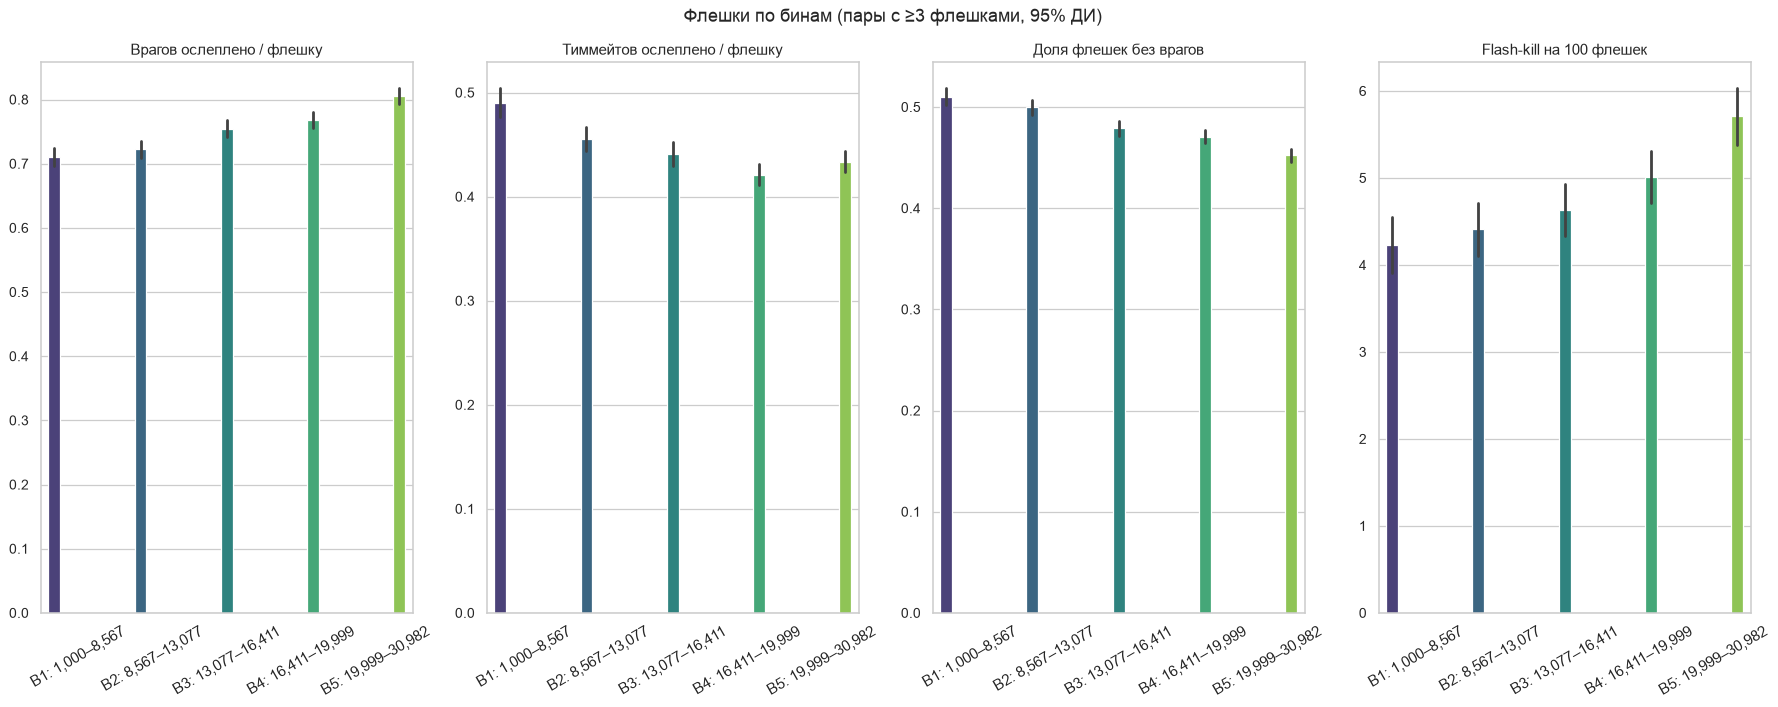

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(20, 8))
titles = {'flash_enemies_per_flash': 'Врагов ослеплено / флешку', 'flash_team_per_flash': 'Тиммейтов ослеплено / флешку',
          'flash_empty_share': 'Доля флешек без врагов', 'flash_kills_per100': 'Flash-kill на 100 флешек'}
for ax, f in zip(axes, FLASH_FEATS):
    sns.barplot(data=pm, x='bin_label', y=f, hue='bin_label', palette=BIN_PALETTE, errorbar=('se', 1.96), legend=False, ax=ax)
    ax.set_title(titles[f], fontsize=12); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=30, labelsize=12)
fig.suptitle(f'Флешки по бинам (пары с ≥{MIN_N} флешками, 95% ДИ)')
plt.tight_layout(); plt.show()

## 6. Профиль по бину: эффективность HE

- `he_dmg_per_throw` — урон по врагам за бросок, **HP + броня** (`HealthDamage + ArmorDamage`);
- `he_zero_share` — доля HE, не нанёсших врагам никакого урона.

Метрики считаем только для пар с **≥ 3 HE** за матч. HE покупают реже флешек, поэтому порог отбрасывает заметную часть пар (см. таблицу).

**Оговорка:** HE без урона — не обязательно плохой бросок. Это может быть промах, а может быть, что в зоне взрыва в этот момент просто
не было врагов. Отличить одно от другого нельзя: позиций врагов вне моментов урона или ослепления в данных нет (раздел 2, «только утилити»).
Поэтому `he_zero_share` в бине — описание того, как часто HE не находит цель, а не прямая оценка качества бросков.

In [10]:
HE_FEATS = ['he_dmg_per_throw', 'he_zero_share']
he_pm = (tr[tr['grenade_type'] == 'he'].assign(zero=lambda d: d['dmg_total'] == 0)
         .groupby(KEY).agg(he_dmg_per_throw=('dmg_total', 'mean'), he_zero_share=('zero', 'mean')))
pm = pm.drop(columns=HE_FEATS, errors='ignore').join(he_pm)
pm[HE_FEATS] = pm[HE_FEATS].where(pm['n_he'] >= MIN_N)

display(threshold_report('n_he'))
he_prof = pm.groupby('bin_label', observed=True)[HE_FEATS].mean()
he_prof

,пар в бине,≥1 бросок,≥3 (в профиле),отброшено (1..MIN_N-1),доля отброшенных из ≥1
bin_label,,,,,
"B1: 1,000–8,567",4880,4276,3224,1052,0.246
"B2: 8,567–13,077",4877,4480,3558,922,0.206
"B3: 13,077–16,411",4879,4569,3799,770,0.169
"B4: 16,411–19,999",5011,4752,4077,675,0.142
"B5: 19,999–30,982",4746,4460,3857,603,0.135


,he_dmg_per_throw,he_zero_share
bin_label,,
"B1: 1,000–8,567",12.263,0.665
"B2: 8,567–13,077",12.964,0.645
"B3: 13,077–16,411",13.633,0.629
"B4: 16,411–19,999",13.828,0.626
"B5: 19,999–30,982",14.511,0.609


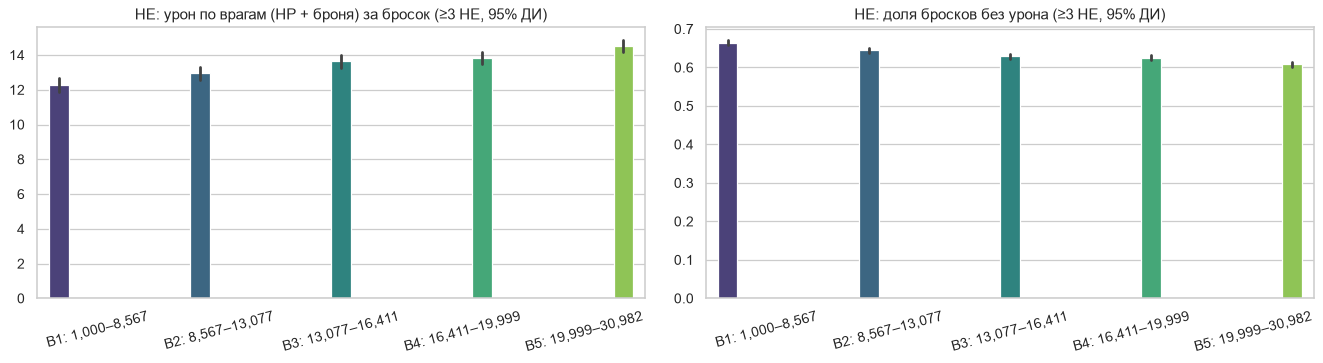

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, f, t in zip(axes, HE_FEATS, ['HE: урон по врагам (HP + броня) за бросок', 'HE: доля бросков без урона']):
    sns.barplot(data=pm, x='bin_label', y=f, hue='bin_label', palette=BIN_PALETTE, errorbar=('se', 1.96), legend=False, ax=ax)
    ax.set_title(f'{t} (≥{MIN_N} HE, 95% ДИ)', fontsize=12); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

## 7. Профиль по бину: молотов

Те же метрики, что для HE: `molotov_dmg_per_throw` (HP + броня) и `molotov_zero_share`; порог — **≥ 3 молотова** за матч.

**Оговорка:** молотов без урона — не обязательно ошибка. Часто его бросают, чтобы закрыть проход или выгнать игрока с позиции
(area denial), и успех — это когда враг *не пошёл* через огонь. Таких исходов в данных нет, а площадь огня (`ConvexHull3D`) почти всегда пуста.
Поэтому высокая доля молотовов без урона в бине — описание поведения, а не оценка качества.

In [12]:
MOLOTOV_FEATS = ['molotov_dmg_per_throw', 'molotov_zero_share']
mo_pm = (tr[tr['grenade_type'] == 'molotov'].assign(zero=lambda d: d['dmg_total'] == 0)
         .groupby(KEY).agg(molotov_dmg_per_throw=('dmg_total', 'mean'), molotov_zero_share=('zero', 'mean')))
pm = pm.drop(columns=MOLOTOV_FEATS, errors='ignore').join(mo_pm)
pm[MOLOTOV_FEATS] = pm[MOLOTOV_FEATS].where(pm['n_molotov'] >= MIN_N)

display(threshold_report('n_molotov'))
mo_prof = pm.groupby('bin_label', observed=True)[MOLOTOV_FEATS].mean()
mo_prof

,пар в бине,≥1 бросок,≥3 (в профиле),отброшено (1..MIN_N-1),доля отброшенных из ≥1
bin_label,,,,,
"B1: 1,000–8,567",4880,4024,2641,1383,0.344
"B2: 8,567–13,077",4877,4213,2981,1232,0.292
"B3: 13,077–16,411",4879,4314,3200,1114,0.258
"B4: 16,411–19,999",5011,4522,3505,1017,0.225
"B5: 19,999–30,982",4746,4300,3454,846,0.197


,molotov_dmg_per_throw,molotov_zero_share
bin_label,,
"B1: 1,000–8,567",2.426,0.876
"B2: 8,567–13,077",2.273,0.867
"B3: 13,077–16,411",2.454,0.867
"B4: 16,411–19,999",2.409,0.864
"B5: 19,999–30,982",2.559,0.852


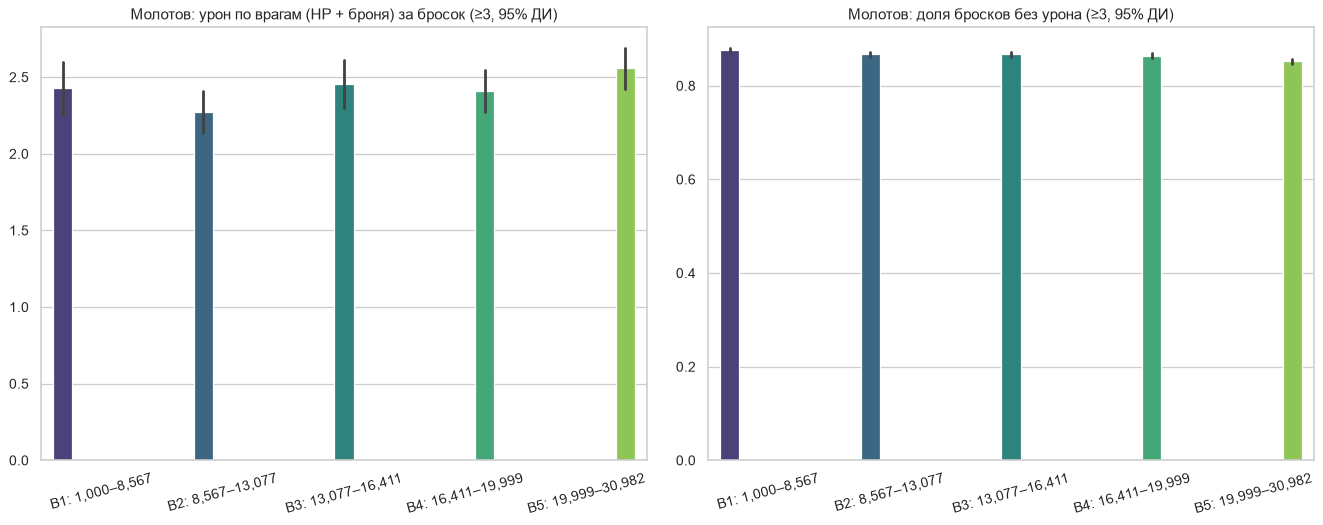

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, f, t in zip(axes, MOLOTOV_FEATS, ['Молотов: урон по врагам (HP + броня) за бросок', 'Молотов: доля бросков без урона']):
    sns.barplot(data=pm, x='bin_label', y=f, hue='bin_label', palette=BIN_PALETTE, errorbar=('se', 1.96), legend=False, ax=ax)
    ax.set_title(f'{t} (≥{MIN_N}, 95% ДИ)', fontsize=12); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

## 8. Профиль по бину: тайминг бросков по раунду

`t_in_round` — секунды от **первой гранаты раунда (любого игрока)** до броска. Это не настоящее время от начала раунда
(тика окончания freeze time в данных нет), но для сравнения бинов в одинаковых условиях прокси годится.
Для каждой пары берём среднее `t_in_round` по броскам типа (при **≥ 3 бросках** типа), потом усредняем по бину.
Среднее чувствительно к поздним броскам (длинный хвост к концу раунда), поэтому рядом показываем и медиану по броскам.

пар с ≥3 бросками типа,smoke,flash,he,molotov
bin_label,,,,
"B1: 1,000–8,567",3320,2958,3224,2641
"B2: 8,567–13,077",3710,3359,3558,2981
"B3: 13,077–16,411",3999,3557,3799,3200
"B4: 16,411–19,999",4287,3884,4077,3505
"B5: 19,999–30,982",4045,3762,3857,3454


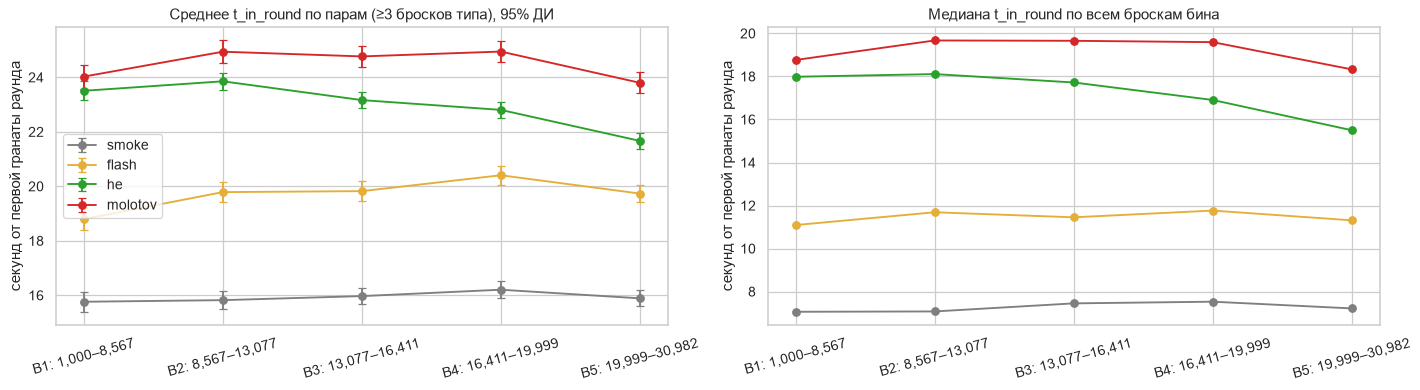

,t_in_round_smoke,t_in_round_flash,t_in_round_he,t_in_round_molotov
bin_label,,,,
"B1: 1,000–8,567",15.764,18.798,23.504,24.026
"B2: 8,567–13,077",15.823,19.787,23.853,24.939
"B3: 13,077–16,411",15.972,19.823,23.163,24.766
"B4: 16,411–19,999",16.206,20.406,22.804,24.944
"B5: 19,999–30,982",15.890,19.734,21.667,23.798


grenade_type,медиана_smoke,медиана_flash,медиана_he,медиана_molotov
bin_label,,,,
"B1: 1,000–8,567",7.062,11.094,17.984,18.766
"B2: 8,567–13,077",7.078,11.688,18.109,19.672
"B3: 13,077–16,411",7.453,11.453,17.719,19.656
"B4: 16,411–19,999",7.531,11.766,16.906,19.594
"B5: 19,999–30,982",7.219,11.312,15.500,18.328


In [14]:
TIMING_FEATS = [f't_in_round_{g}' for g in GT_ORDER]
t_pm = tr.groupby(KEY + ['grenade_type'])['t_in_round'].mean().unstack().reindex(columns=GT_ORDER).add_prefix('t_in_round_')
pm = pm.drop(columns=TIMING_FEATS, errors='ignore').join(t_pm)
for g in GT_ORDER:
    pm[f't_in_round_{g}'] = pm[f't_in_round_{g}'].where(pm[f'n_{g}'] >= MIN_N)

display(pd.concat({g: threshold_report(f'n_{g}')[f'≥{MIN_N} (в профиле)'] for g in GT_ORDER}, axis=1)
        .rename_axis(columns=f'пар с ≥{MIN_N} бросками типа'))
t_prof = pm.groupby('bin_label', observed=True)[TIMING_FEATS].mean()
t_ci = 1.96 * pm.groupby('bin_label', observed=True)[TIMING_FEATS].sem()  # 95% ДИ среднего бина
t_median = tr.groupby(['bin_label', 'grenade_type'], observed=True)['t_in_round'].median().unstack().reindex(columns=GT_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for g in GT_ORDER:
    axes[0].errorbar(range(N_BINS), t_prof[f't_in_round_{g}'], yerr=t_ci[f't_in_round_{g}'], marker='o', capsize=3,
                     color=GT_COLORS[g], label=g)
    axes[1].plot(range(N_BINS), t_median[g], marker='o', color=GT_COLORS[g], label=g)
for ax, t in zip(axes, [f'Среднее t_in_round по парам (≥{MIN_N} бросков типа), 95% ДИ', 'Медиана t_in_round по всем броскам бина']):
    ax.set_xticks(range(N_BINS), BIN_LABELS, rotation=15); ax.set_title(t); ax.set_ylabel('секунд от первой гранаты раунда')
axes[0].legend()
plt.tight_layout(); plt.show()
display(t_prof)
t_median.add_prefix('медиана_')

## 9. Сводная таблица профилей бинов

Все признаки в одной таблице **бин × метрика**. Значение — среднее по парам «игрок–матч» бина, у которых метрика определена
(прошла порог `MIN_N`). Это и есть центроиды, которые читает ноутбук 2.

Тепловая карта ниже — те же числа, нормированные по каждой метрике между бинами (z-score по 5 бинам), чтобы было видно направление
изменения. Цвет — только «выше/ниже среднего по бинам», а не «лучше/хуже». Подписи — среднее ± 95% ДИ среднего.

**Два разных числа разброса — на два разных вопроса:**
- **std внутри бина** (`<feature>_std` в файле) — насколько разные игроки-матчи одного бина. Отвечает на вопрос «типичен ли
  конкретный игрок для бина»; им ноутбук 2 нормирует отклонение игрока.
- **95% ДИ среднего** = ±1.96·std/√n — насколько точно мы знаем сам центроид. Отвечает на вопрос «различаются ли средние двух бинов».

ДИ в 25–35 раз уже std. Поэтому одновременно верно и «средние B1 и B5 различаются надёжно», и «игроки B1 и B5 почти не различаются».
Вторая таблица ниже: для каждой метрики — std, макс. полуширина ДИ и перекрываются ли ДИ соседних бинов («перекр.»).
Неперекрывающиеся ДИ — достаточный (консервативный) признак различия; перекрытие не доказывает равенство, но и права утверждать
разницу не даёт.

bin_label,"B1: 1,000–8,567","B2: 8,567–13,077","B3: 13,077–16,411","B4: 16,411–19,999","B5: 19,999–30,982",все с рейтингом
nades_per_round,0.961,1.115,1.200,1.295,1.349,1.184
share_smoke,0.303,0.310,0.318,0.314,0.310,0.311
share_flash,0.253,0.254,0.253,0.255,0.259,0.255
share_he,0.254,0.251,0.248,0.247,0.241,0.248
share_molotov,0.190,0.185,0.180,0.184,0.190,0.186
flash_enemies_per_flash,0.711,0.722,0.755,0.768,0.805,0.755
flash_team_per_flash,0.490,0.456,0.441,0.421,0.434,0.446
flash_empty_share,0.510,0.500,0.479,0.471,0.452,0.481
flash_kills_per100,4.228,4.409,4.634,5.012,5.706,4.836
he_dmg_per_throw,12.263,12.964,13.633,13.828,14.511,13.491


,std внутри бина (ср. по бинам),±95% ДИ среднего (макс. по бинам),std / ДИ,размах B1–B5,ДИ B1/B2,ДИ B2/B3,ДИ B3/B4,ДИ B4/B5,соседних пар с перекрытием ДИ
nades_per_round,0.640,0.019,34,0.388,·,·,·,·,0
share_smoke,0.157,0.005,30,0.015,перекр.,перекр.,перекр.,перекр.,4
share_flash,0.156,0.005,30,0.006,перекр.,перекр.,перекр.,перекр.,4
share_he,0.132,0.005,29,0.013,перекр.,перекр.,перекр.,перекр.,4
share_molotov,0.115,0.004,29,0.009,перекр.,перекр.,перекр.,перекр.,4
flash_enemies_per_flash,0.388,0.014,27,0.094,перекр.,·,перекр.,·,2
flash_team_per_flash,0.341,0.014,25,0.069,·,перекр.,перекр.,перекр.,3
flash_empty_share,0.217,0.008,27,0.058,перекр.,·,перекр.,·,2
flash_kills_per100,9.309,0.323,29,1.478,перекр.,перекр.,перекр.,·,3
he_dmg_per_throw,11.502,0.398,29,2.249,перекр.,перекр.,перекр.,перекр.,4


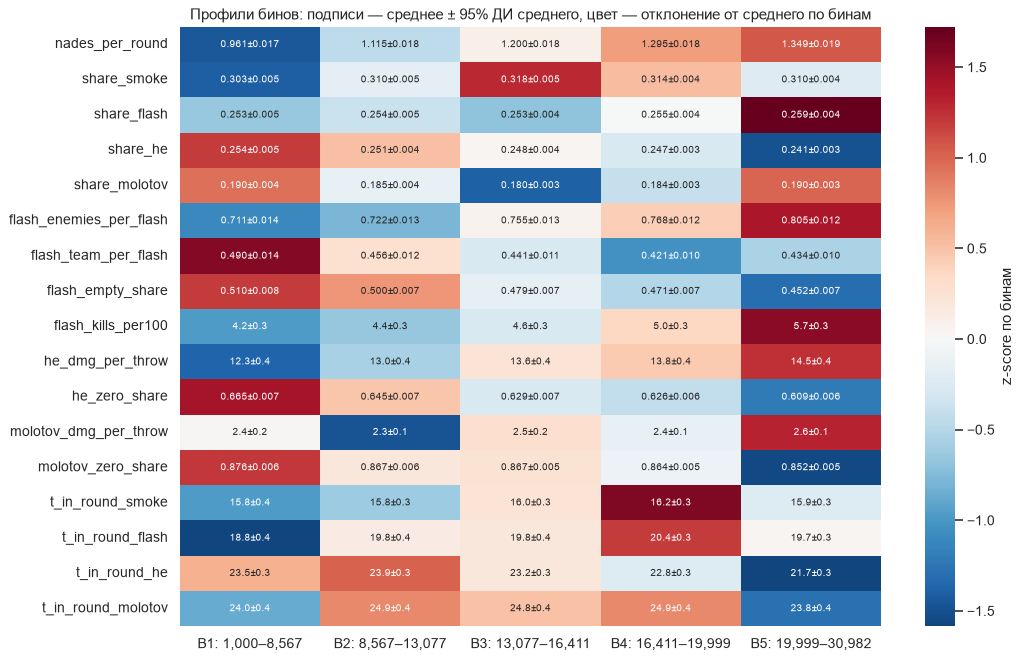

In [15]:
FEATURES = ['nades_per_round'] + MIX_FEATS + FLASH_FEATS + HE_FEATS + MOLOTOV_FEATS + TIMING_FEATS
g = pm.groupby('bin_label', observed=True)
PROFILE = g[FEATURES].mean()
PROFILE_STD = g[FEATURES].std()
PROFILE_N = g[FEATURES].count()
# 95% ДИ среднего бина: ±1.96·SE, SE = std / sqrt(n). Это точность центроида, а не разброс игроков (он — PROFILE_STD)
PROFILE_CI = 1.96 * PROFILE_STD / np.sqrt(PROFILE_N)

overview = PROFILE.T.copy()
overview['все с рейтингом'] = pm[FEATURES].mean()
display(overview.style.format('{:.3f}').background_gradient(axis=1, cmap='Blues', subset=BIN_LABELS))

# std (разброс игроков) против 95% ДИ среднего (точность центроида); перекрываются ли ДИ соседних бинов
ci_lo, ci_hi = PROFILE - PROFILE_CI, PROFILE + PROFILE_CI
ci_vs_std = pd.DataFrame({
    'std внутри бина (ср. по бинам)': PROFILE_STD.mean(),
    '±95% ДИ среднего (макс. по бинам)': PROFILE_CI.max(),
    'std / ДИ': PROFILE_STD.mean() / PROFILE_CI.max(),
    'размах B1–B5': PROFILE.max() - PROFILE.min(),
})
for i in range(N_BINS - 1):
    overlap = (ci_lo.iloc[i + 1] <= ci_hi.iloc[i]) & (ci_lo.iloc[i] <= ci_hi.iloc[i + 1])
    ci_vs_std[f'ДИ B{i + 1}/B{i + 2}'] = np.where(overlap, 'перекр.', '·')
ci_vs_std['соседних пар с перекрытием ДИ'] = (ci_vs_std.filter(like='ДИ B') == 'перекр.').sum(axis=1)
display(ci_vs_std.style.format({c: '{:.3f}' for c in ci_vs_std.columns[:4]} | {'std / ДИ': '{:.0f}'}))

z = (PROFILE - PROFILE.mean()) / PROFILE.std()
annot = pd.DataFrame({b: [f'{m:.3f}±{c:.3f}' if abs(m) < 2 else f'{m:.1f}±{c:.1f}'
                          for m, c in zip(PROFILE.loc[b], PROFILE_CI.loc[b])] for b in BIN_LABELS}, index=FEATURES)
fig, ax = plt.subplots(figsize=(12, 7.5))
sns.heatmap(z.T, annot=annot, fmt='', annot_kws={'fontsize': 8}, cmap='RdBu_r', center=0, ax=ax,
            cbar_kws={'label': 'z-score по бинам'})
ax.set_title('Профили бинов: подписи — среднее ± 95% ДИ среднего, цвет — отклонение от среднего по бинам')
ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

## 10. Выводы по бинам

Для каждого бина сравниваем метрики с соседними бинами (B1 — только с B2, B5 — только с B4). В таблице разница со средним по соседям,
делённая на разброс метрики между бинами: положительное — у бина значение выше, чем у соседей. Тексты ниже написаны по этим числам
и по таблице раздела 9.

**Осторожно с этой таблицей:** она нормирована на разброс *между* бинами. У почти плоских метрик (микс, урон молотова) даже разница
в доли процента выглядит как ±1.5. Поэтому ниже есть вторая таблица — насколько бины вообще различаются относительно разброса *внутри* бина, с полушириной
95% ДИ среднего для сравнения. Разницу между соседними бинами ниже называем различием, только если их ДИ не перекрываются
(таблица ДИ в разделе 9); иначе пишем «в пределах ДИ».

In [16]:
neigh = pd.DataFrame({lab: PROFILE.iloc[[j for j in (i - 1, i + 1) if 0 <= j < N_BINS]].mean()
                      for i, lab in enumerate(BIN_LABELS)}).T
vs_neighbors = (PROFILE - neigh) / PROFILE.std()
vs_neighbors.T.style.format('{:+.2f}').background_gradient(cmap='RdBu_r', vmin=-2, vmax=2)

bin_label,"B1: 1,000–8,567","B2: 8,567–13,077","B3: 13,077–16,411","B4: 16,411–19,999","B5: 19,999–30,982"
nades_per_round,-1.01,+0.23,-0.03,+0.13,+0.35
share_smoke,-1.25,-0.10,+1.10,-0.00,-0.75
share_flash,-0.27,+0.29,-0.49,-0.53,+1.73
share_he,+0.68,-0.10,-0.09,+0.46,-1.22
share_molotov,+1.09,+0.08,-1.12,-0.21,+1.40
flash_enemies_per_flash,-0.31,-0.28,+0.25,-0.31,+0.98
flash_team_per_flash,+1.31,-0.38,+0.11,-0.62,+0.48
flash_empty_share,+0.45,+0.23,-0.28,+0.22,-0.80
flash_kills_per100,-0.31,-0.04,-0.13,-0.27,+1.18
he_dmg_per_throw,-0.82,+0.02,+0.28,-0.28,+0.80


In [17]:
# насколько бины различаются: размах средних B1..B5 против разброса внутри бина (объединённое std по бинам)
pooled_std = np.sqrt(((PROFILE_N - 1) * PROFILE_STD ** 2).sum() / (PROFILE_N - 1).sum())
separation = pd.DataFrame({
    'размах между бинами': PROFILE.max() - PROFILE.min(),
    'std внутри бина (объединённое)': pooled_std,
    '±95% ДИ среднего (макс. по бинам)': PROFILE_CI.max(),
})
separation['размах / std внутри'] = separation['размах между бинами'] / separation['std внутри бина (объединённое)']
separation.sort_values('размах / std внутри', ascending=False)

,размах между бинами,std внутри бина (объединённое),±95% ДИ среднего (макс. по бинам),размах / std внутри
nades_per_round,0.388,0.640,0.019,0.606
flash_empty_share,0.058,0.217,0.008,0.268
he_zero_share,0.056,0.209,0.007,0.266
flash_enemies_per_flash,0.094,0.387,0.014,0.244
t_in_round_he,2.186,9.662,0.348,0.226
flash_team_per_flash,0.069,0.340,0.014,0.204
he_dmg_per_throw,2.249,11.506,0.398,0.195
flash_kills_per100,1.478,9.345,0.323,0.158
molotov_zero_share,0.024,0.152,0.006,0.158
t_in_round_flash,1.608,10.753,0.393,0.150


**Общее.**
- **Монотонно с рейтингом** (от B1 к B5) растут гранаты за раунд (0.96 → 1.35), врагов на флешку (0.71 → 0.81), flash-kill на 100 флешек
  (4.2 → 5.7) и урон HE за бросок (12.3 → 14.5 HP). Падают доля пустых флешек (51% → 45%) и доля HE без урона (66.5% → 60.9%).
  Разница B1–B5 по всем этим метрикам во много раз больше 95% ДИ средних, то есть тренды не случайные. Но **шаг между соседними
  бинами** надёжно виден (ДИ не перекрываются на всех 4 шагах) только у гранат за раунд. У остальных часть соседних пар
  в пределах ДИ: урон HE — все 4 шага, flash-kill — все, кроме B4→B5, пустые флешки и врагов на флешку — B1/B2 и B3/B4,
  доля HE без урона — B3/B4.
- **Почти плоско:** микс гранат (каждая доля меняется меньше чем на 1.5 п.п.), урон молотова (2.3–2.6 HP) и тайминг смоков (15.8–16.2 с) —
  ДИ всех соседних бинов перекрываются.
- **Бины сильно перекрываются.** Даже у самой различающей метрики (гранаты за раунд) размах B1–B5 — 0.6 стандартного отклонения
  внутри бина, у остальных — 0.3 и меньше. Типичный игрок-матч из B1 и из B5 по утилити почти неотличим. Узкие ДИ этого не отменяют:
  они говорят о точности средних, а не о том, что игроки бинов разные. Для ноутбука 2 это главное ограничение: ближайший центроид
  по **одному** матчу будет ошибаться часто. Надёжнее усреднять признаки игрока по нескольким матчам и давать больший вес первым
  метрикам из таблицы выше.

**По бинам** (в этом бине в среднем…; «в пределах ДИ» — разница с соседом не выходит за 95% ДИ):
- **B1 (1 000–8 567).** Меньше всего утилити: 0.96 гранаты за раунд против 1.12 в B2 (самый большой шаг между соседними бинами).
  Флешки: больше всего ослеплённых тиммейтов (0.49 на флешку против 0.46 в B2). Пустых флешек больше всех (51%), врагов на флешку
  меньше всех (0.71), но от B2 (50% и 0.72) — в пределах ДИ. HE: самая высокая доля без урона (66.5% против 64.5% в B2)
  и самый низкий урон (12.3 HP; от B2 — в пределах ДИ). Флешки бросает раньше всех (18.8 с против 19.8 в B2).
  Смоков в миксе меньше всех (30.3%), но от B2 — в пределах ДИ. Чаще всех не проходит порог: у 26% бросавших флешки их меньше трёх за матч.
- **B2 (8 567–13 077).** Переходный бин: по всем монотонным метрикам между B1 и B3. Заметно меньше ослеплённых тиммейтов, чем в B1 (0.46),
  но врагов на флешку почти столько же (0.72 против 0.71). У молотова самый низкий урон (2.27 HP), но это в пределах ДИ.
- **B3 (13 077–16 411).** Больше всего смоков в миксе (31.8%), меньше всего молотовов (18.0%) — оба отличия от соседей в пределах ДИ.
  Флешки и HE — ровно посередине шкалы (0.76 врага на флешку, 13.6 HP за HE).
- **B4 (16 411–19 999).** Меньше всего ослеплённых тиммейтов (0.42 на флешку), но от B3 и B5 (0.44 и 0.43) — в пределах ДИ.
  Позже всех бросает флешки (20.4 с; от B3 — в пределах ДИ, от B5 — ровно на границе ДИ); тайминг смоков (16.2 с) от соседей не отличается.
  По HE почти не отличается от B3: доля без урона 62.6% против 62.9%, урон 13.8 против 13.6 HP.
- **B5 (19 999–30 982).** Больше всего утилити (1.35 за раунд). Лучшие значения по флешкам и HE: 0.81 врага на флешку, 45% пустых,
  5.7 flash-kill на 100 флешек (против 5.0 в B4 — единственный шаг по flash-kill за пределами ДИ), 14.5 HP за HE (от B4 — в пределах ДИ),
  60.9% HE без урона. Меньше всего молотовов без урона (85.2% против 86.5% в B4). HE и молотовы бросает раньше B4 (21.7 и 23.8 с
  против 22.8 и 24.9); HE — раньше всех бинов, молотовы — наравне с B1 (24.0 с, в пределах ДИ).
  Доля флешек в миксе самая высокая (25.9%), HE — самая низкая (24.1%), ослеплённых тиммейтов немного больше, чем в B4, —
  все три отличия от B4 в пределах ДИ.

Всё это — описание того, чем бины отличаются в среднем, а не причины рейтинга.

## 11. Экспорт профиля для ноутбука 2

Сохраняем профиль в **`data/processed/rating_bin_profiles.parquet`** — одна строка на бин, широкий формат.

**Схема файла:**

| колонка | тип | смысл |
|---|---|---|
| `bin` | int | номер бина, 1 (низкий рейтинг) … 5 (высокий) |
| `bin_label` | str | подпись, например `B1: 1,000–8,567` |
| `rating_lo`, `rating_hi` | float | границы бина по `PremierRatingNew` (из `pd.qcut`); интервал `(rating_lo, rating_hi]`, у B1 левая граница включена |
| `n_player_matches` | int | пар «игрок–матч» в бине |
| `min_n` | int | порог бросков типа за матч (`MIN_N` = 3), с которым считались метрики по типам |
| `<feature>` | float | **центроид**: среднее признака по парам бина |
| `<feature>_std` | float | стандартное отклонение признака внутри бина |
| `<feature>_n` | int | сколько пар бина участвовало в среднем (прошло порог) |

**Признаки (`<feature>`, 17 штук).** Все считаются **на одного игрока за один матч**, потом усредняются по бину:
- `nades_per_round` — всего гранат / раундов в матче (раунды = макс. раунд с гранатой + 1). Определён всегда;
- `share_smoke`, `share_flash`, `share_he`, `share_molotov` — доля типа среди бросков игрока за матч; NaN, если бросков < 3;
- `flash_enemies_per_flash`, `flash_team_per_flash` — среднее число ослеплённых врагов / тиммейтов (без себя) на флешку;
  `flash_empty_share` — доля флешек без ослеплённых врагов; `flash_kills_per100` — убийства ослеплённых этой флешкой врагов на 100 флешек;
  NaN, если флешек < 3;
- `he_dmg_per_throw`, `he_zero_share` — урон по врагам (HP + броня) за HE и доля HE с нулевым уроном; NaN, если HE < 3;
- `molotov_dmg_per_throw`, `molotov_zero_share` — то же для молотовов; NaN, если молотовов < 3;
- `t_in_round_smoke`, `t_in_round_flash`, `t_in_round_he`, `t_in_round_molotov` — среднее время броска (с) от первой гранаты раунда
  (любого игрока); NaN, если бросков типа < 3.

**Как ноутбуку 2 использовать файл:**
- **игрок с рейтингом** → бин по границам: `pd.cut(rating, [-inf, *rating_hi[:-1], inf], labels=bin)` (рейтинги вне диапазона уходят в крайние бины);
- **игрок без рейтинга** → считаем те же признаки тем же способом (и с тем же `min_n`) и ищем ближайший центроид. Признаки в разных шкалах
  (доли, HP, секунды), поэтому расстояние нужно считать по стандартизованным разностям, например делить на внутрибиновое стандартное отклонение,
  объединённое по бинам: `sqrt(Σ(n_b − 1)·std_b² / Σ(n_b − 1))` из колонок `<feature>_std` и `<feature>_n`. Признаки, которые у игрока NaN, пропускаем.
  Доли микса в сумме дают 1, то есть линейно зависимы. Это ок для ближайшего центроида, но лучше учитывать при взвешивании.
- **Бины сильно перекрываются** (раздел 10): размах центроидов — 0.6 внутрибинового std у лучшей метрики и ≤ 0.3 у остальных.
  Отнесение к бину по одному матчу будет неуверенным; признаки игрока лучше усреднять по нескольким матчам.

In [18]:
profile_out = pd.DataFrame({
    'bin': range(1, N_BINS + 1),
    'bin_label': BIN_LABELS,
    'rating_lo': BIN_EDGES[:-1],
    'rating_hi': BIN_EDGES[1:],
    'n_player_matches': pm.groupby('bin_label', observed=True).size().values,
    'min_n': MIN_N,
})
for f in FEATURES:
    profile_out[f] = PROFILE[f].values.astype('float64')
    profile_out[f'{f}_std'] = PROFILE_STD[f].values.astype('float64')
    profile_out[f'{f}_n'] = PROFILE_N[f].values

profile_out.to_parquet(PROFILE_PATH, index=False)

check = pd.read_parquet(PROFILE_PATH)
print(f'Сохранено: {PROFILE_PATH}  shape={check.shape}')
print('Признаки-центроиды:', FEATURES)
check.T

Сохранено: ../data/processed/rating_bin_profiles.parquet  shape=(5, 57)
Признаки-центроиды: ['nades_per_round', 'share_smoke', 'share_flash', 'share_he', 'share_molotov', 'flash_enemies_per_flash', 'flash_team_per_flash', 'flash_empty_share', 'flash_kills_per100', 'he_dmg_per_throw', 'he_zero_share', 'molotov_dmg_per_throw', 'molotov_zero_share', 't_in_round_smoke', 't_in_round_flash', 't_in_round_he', 't_in_round_molotov']


,0,1,2,3,4
bin,1,2,3,4,5
bin_label,"B1: 1,000–8,567","B2: 8,567–13,077","B3: 13,077–16,411","B4: 16,411–19,999","B5: 19,999–30,982"
rating_lo,"1,000.000","8,567.000","13,076.800","16,411.200","19,999.000"
rating_hi,"8,567.000","13,076.800","16,411.200","19,999.000","30,982.000"
n_player_matches,4880,4877,4879,5011,4746
min_n,3,3,3,3,3
nades_per_round,0.961,1.115,1.200,1.295,1.349
nades_per_round_std,0.621,0.638,0.631,0.650,0.661
nades_per_round_n,4874,4873,4876,5002,4728
share_smoke,0.303,0.310,0.318,0.314,0.310
